# Q1 · Asking-price distribution and anomaly screening

## TL;DR

- The source records **32,895 zero prices (7.71%)** and **1,951 listings at \$1**. Among **393,985 positive prices**, the median is **\$15,000**. The 5% trimmed mean is **\$17,624**, compared with the untrimmed mean of **\$81,478**.
- The **\$500–\$150,000** band retains **97.62%** of positive prices. The median rises to **\$15,900**, and the share excluded varies by vehicle type and state.
- Price endings remain concentrated within the sensitivity band. Endings of **95** and **99** account for **18.03%** and **8.79%** of in-band prices, respectively. These patterns can reflect how sellers set or enter prices.
- Among **244,038 in-band listings** eligible for the peer screen, **5,286 (2.17%)** still lie unusually far from their make/type/age peers under the stated robust rule.


## Context and methods

The [proposal](../docs/proposal.md) asks how listing prices are distributed and which values deserve further review. We use Austin Reese’s [Craigslist Cars & Trucks Data, Kaggle v10](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data/versions/10), with valid posting dates from April 4 to May 4, 2021. A listing is the unit of analysis. These prices describe seller asks in the observed snapshot.

**Scope.** The source audit includes zero prices. The distribution starts with all finite positive prices. The inclusive \$500–\$150,000 band is a sensitivity cohort shared with [Notebook 05](05_adjusted_associations_and_prediction.ipynb). The two screens flag prices for inspection. They provide different lenses on unusual listings.

**Key assumptions.** The pinned source has unique populated listing IDs, which makes the source-to-positive reconciliation exact. The same vehicle may appear in multiple listings. Percentages and quantiles describe this snapshot. Changes across price rules are comparisons of nested cohorts.


## Data and setup

The notebook reads the same locally downloaded file as [Notebook 02](02_clean_and_derive.ipynb). See [DATA.md](../DATA.md) for download instructions. Displayed outputs are aggregate tables and figures.


In [1]:
import json
from pathlib import Path
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/listings.py").is_file())
sys.path.insert(0, str(ROOT))

from src.listings import HIGH_PRICE_REVIEW, LOW_PRICE_REVIEW
from src.q1_price_analysis import (
    BAND, cohort_summary, contextual_screening, group_screening, heaping, heaping_figure,
    load_price_inputs, peer_figure, price_audit, price_distribution, probability,
    save_figure, screening_figure, setup_plots, tail_figure,
)

%matplotlib inline
setup_plots()
OUTPUT = ROOT / "outputs" / "q1"
OUTPUT.mkdir(parents=True, exist_ok=True)

positive, source, cleaning_audit = load_price_inputs(ROOT)
prices = positive["price"]
source_prices = source["price"]
band = prices[prices.between(LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW)]


## Results

### 1. Reconcile the source, positive listings and sensitivity cohort

Source percentages use all input listings as the denominator. Prices exactly at either screening cutoff remain in the band.


In [2]:
source_audit = price_audit(source_prices)
display(source_audit.style.format({"Listings": "{:,.0f}", "% of source listings": "{:.3f}"}))
assert len(prices) == source_prices.gt(0).sum()
assert len(band) == source_prices.between(LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW).sum()
print(f"Positive-price sensitivity cohort retains {len(band):,} of {len(prices):,} listings ({len(band)/len(prices):.2%}).")


,Listings,% of source listings
Unusable or missing,0,0.000
Negative,0,0.000
Exactly $0,"32,895",7.706
Exactly $1,"1,951",0.457
Other positive prices below $500,"7,248",1.698
"Within $500–$150,000","384,590",90.093
"Above $150,000",196,0.046


Positive-price sensitivity cohort retains 384,590 of 393,985 listings (97.62%).


### 2. Measure spread and the influence of extreme values

The 5% trimmed mean removes the lowest and highest 5% of each cohort by rank. This diagnostic complements the median and IQR. Both describe the center with less sensitivity to the very high recorded prices.


,Listings,P05,P25,Median,P75,P95,P99,IQR
All positive,"393,985","1,988","7,000","15,000","27,590","44,999","68,747","20,590"
"$500–$150,000","384,590","2,899","7,800","15,900","27,990","45,225","67,995","20,190"


,P01,Mean,5% trimmed mean,Maximum
All positive,150,"81,478","17,624","3,736,928,711"
"$500–$150,000",944,"19,284","18,030","150,000"


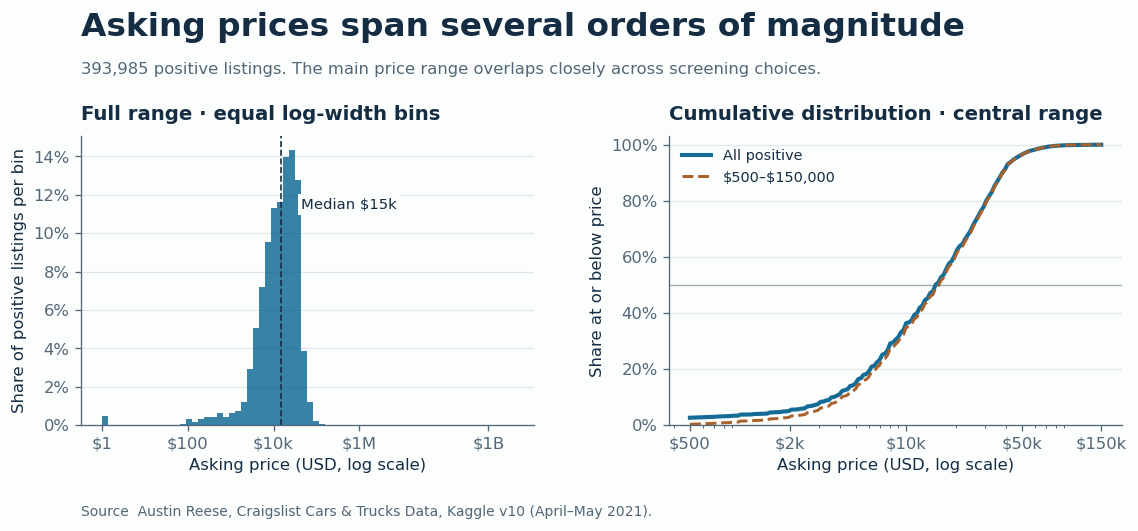

In [3]:
distribution = cohort_summary(prices)
main_columns = ["Listings", "P05", "P25", "Median", "P75", "P95", "P99", "IQR"]
display(distribution[main_columns].style.format("{:,.0f}"))
display(distribution[["P01", "Mean", "5% trimmed mean", "Maximum"]].style.format("{:,.0f}"))
save_figure(price_distribution(prices), OUTPUT, "01_price_distribution")


Across all positive listings, the middle half spans **\$7,000–\$27,590**. After applying the band, the median is **\$900 higher**, and the 99th percentile is slightly lower. The untrimmed mean falls by more than **\$62,000**, so the tail treatment matters much more for the mean than for the median.

### 3. Inspect the two tails separately

The left curve is the share **strictly below** each price. The right curve is the share **strictly above** each price. Probabilities are evaluated on fixed price grids and at the exact screening thresholds. The logarithmic axes make small tail probabilities readable.


,Listings,% of positive
Rule,,
At or below $1,"1,951",0.495
Below $500,"9,199",2.335
"Below $1,000","13,420",3.406
"Above $75,000","2,297",0.583
"Above $150,000",196,0.050
Above $1 million,53,0.013


Above-band records contribute 76.9% of the arithmetic price sum.


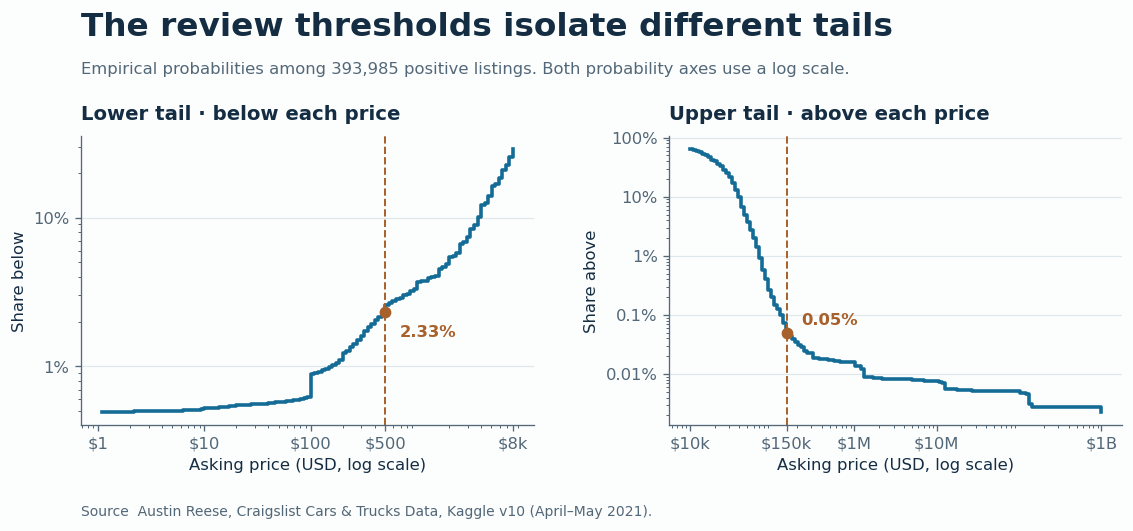

In [4]:
thresholds = [
    ("At or below $1", 1, False, True),
    (f"Below ${LOW_PRICE_REVIEW:,}", LOW_PRICE_REVIEW, False, False),
    ("Below $1,000", 1_000, False, False),
    ("Above $75,000", 75_000, True, False),
    (f"Above ${HIGH_PRICE_REVIEW:,}", HIGH_PRICE_REVIEW, True, False),
    ("Above $1 million", 1_000_000, True, False),
]
tail_rows = []
for label, cutoff, upper, inclusive in thresholds:
    share = probability(prices, [cutoff], upper=upper, inclusive=inclusive)[0]
    tail_rows.append({"Rule": label, "Listings": round(len(prices) * share), "% of positive": 100 * share})
tails = pd.DataFrame(tail_rows).set_index("Rule")
display(tails.style.format({"Listings": "{:,.0f}", "% of positive": "{:.3f}"}))
high_sum_share = prices[prices.gt(HIGH_PRICE_REVIEW)].sum() / prices.sum()
print(f"Above-band records contribute {high_sum_share:.1%} of the arithmetic price sum.")
save_figure(tail_figure(prices), OUTPUT, "02_tail_probabilities")


A total of **9,199** prices fall below \$500, compared with **196** above \$150,000. These two tails have very different frequencies. The lower tail contains a visible \$1 spike. The upper tail contributes most of the arithmetic sum of the recorded prices, making the mean sensitive to a small share of listings. A low or high value alone leaves its origin unresolved.

### 4. Check exact-price heaping

For whole-dollar prices in the sensitivity band, assign one ending category per listing. Multiples of \$1,000, other multiples of \$500, and other multiples of \$100 are counted separately. Endings 95 and 99 refer to the final two digits. Any remaining whole-dollar price goes to “Other.” The exact-value chart shows only the eight most frequent amounts.


Whole-dollar coverage: 384,590 of 384,590 in-band listings (100.00%).


,Listings,%
Other whole-dollar price,"162,047",42.14
Ends in 95,"69,356",18.03
Other multiple of $100,"52,856",13.74
Other multiple of $500,"37,074",9.64
Ends in 99,"33,793",8.79
"Multiple of $1,000","29,464",7.66


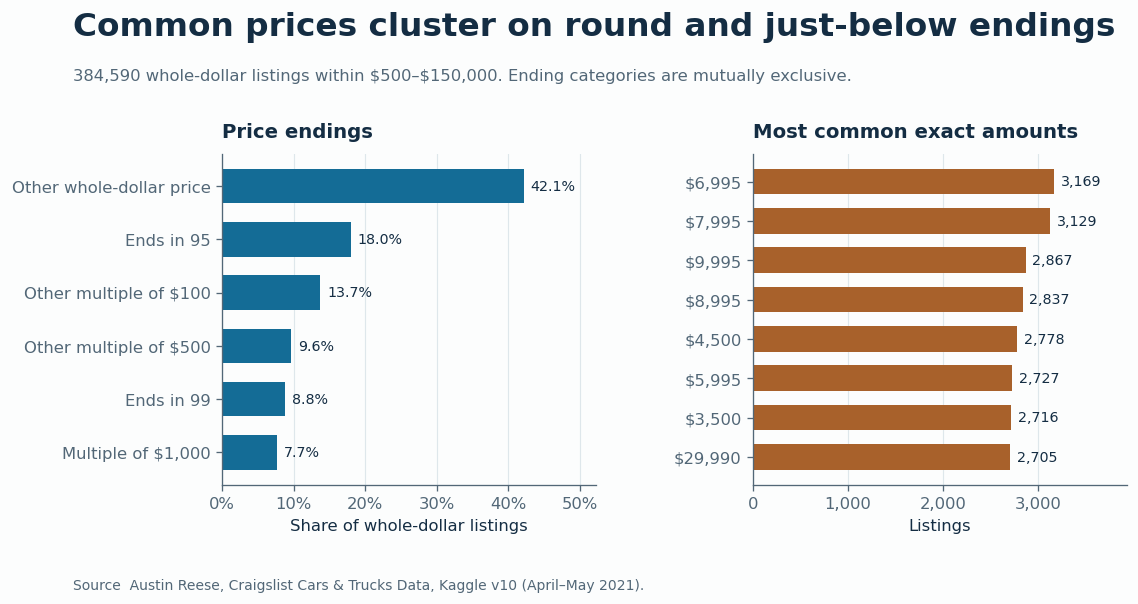

In [5]:
endings, frequent, whole_n, in_band_n = heaping(prices)
print(f"Whole-dollar coverage: {whole_n:,} of {in_band_n:,} in-band listings ({whole_n/in_band_n:.2%}).")
display(endings.style.format({"Listings": "{:,.0f}", "%": "{:.2f}"}))
save_figure(heaping_figure(endings, frequent, whole_n), OUTPUT, "03_price_heaping")


The most frequent in-band amount is **\$6,995**. Rounded and just-below prices are common throughout the retained sample. This supports a distribution with visible spikes, even after the extreme tails are set aside.

### 5. Audit how filtering changes representation

We compare zero rates among **all source listings** with cutoff exposure among **positive listings**. Missing group labels remain visible. For the tables, eligible groups have at least 1,000 positive listings. Vehicle types are shown by source volume, and states by outside-band rate.


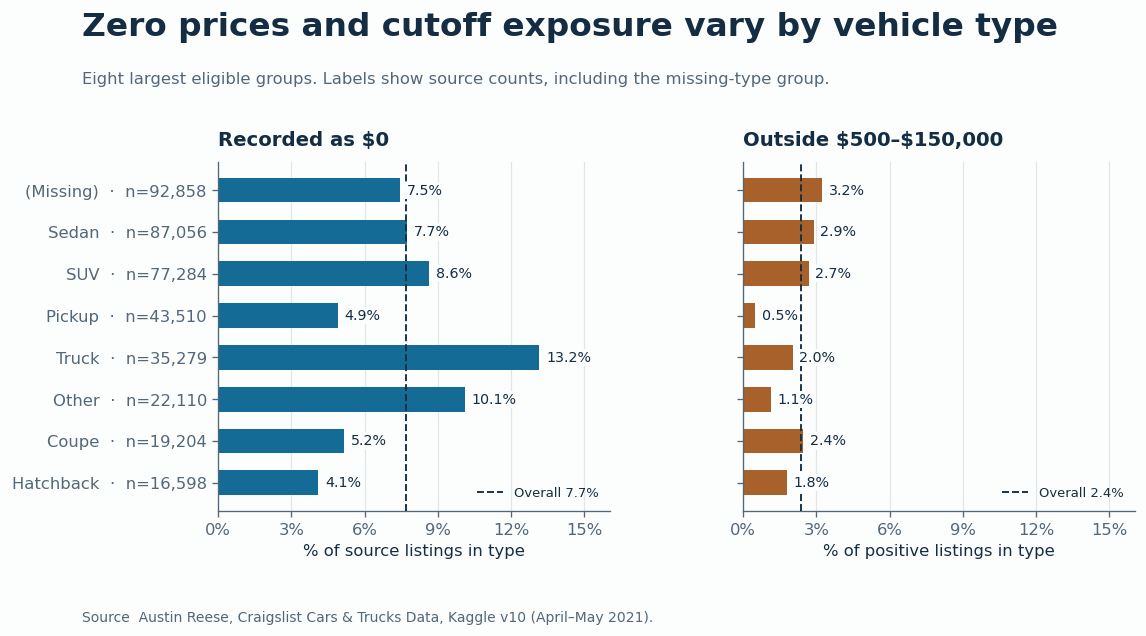

,Source n,Positive,Low,High,Zero % of source,Outside % of positive,Share before %,Share in band %,Share change pp
Group,,,,,,,,,
(missing),"92,858","85,932","2,707",70,7.46,3.23,21.81,21.62,-0.19
sedan,"87,056","80,322","2,314",8,7.74,2.89,20.39,20.28,-0.11
suv,"77,284","70,599","1,886",13,8.65,2.69,17.92,17.86,-0.06
pickup,"43,510","41,373",191,7,4.91,0.48,10.50,10.71,0.21
truck,"35,279","30,634",611,10,13.17,2.03,7.78,7.80,0.03
other,"22,110","19,873",198,27,10.12,1.13,5.04,5.11,0.06
coupe,"19,204","18,214",404,42,5.16,2.45,4.62,4.62,-0.00
hatchback,"16,598","15,917",286,0,4.10,1.80,4.04,4.06,0.02


,Source n,Positive,Low,High,Zero % of source,Outside % of positive,Share before %,Share in band %,Share change pp
Group,,,,,,,,,
me,"2,966","2,761",323,2,6.91,11.77,0.70,0.63,-0.07
or,"17,104","14,260","1,337",7,16.63,9.42,3.62,3.36,-0.26
nh,"2,981","2,944",230,2,1.24,7.88,0.75,0.71,-0.04
hi,"2,964","2,735",184,3,7.73,6.84,0.69,0.66,-0.03
fl,"28,511","27,316","1,324",26,4.19,4.94,6.93,6.75,-0.18
vt,"2,513","2,460",118,0,2.11,4.80,0.62,0.61,-0.02
wa,"13,861","12,473",518,4,10.01,4.19,3.17,3.11,-0.06
ma,"8,174","7,993",329,0,2.21,4.12,2.03,1.99,-0.04


In [6]:
types = group_screening(source, "type")
states = group_screening(source, "state")
makes = group_screening(source, "manufacturer")
zero_rate = 100 * source_prices.eq(0).mean()
outside_rate = 100 * (len(prices) - len(band)) / len(prices)
save_figure(screening_figure(types, zero_rate, outside_rate), OUTPUT, "04_vehicle_type_screening")

columns = ["Source n", "Positive", "Low", "High", "Zero % of source",
           "Outside % of positive", "Share before %", "Share in band %", "Share change pp"]
formatting = {column: "{:.2f}" if "%" in column or column.endswith("pp") else "{:,.0f}"
              for column in columns}
shown_types = types.loc[types["Positive"].ge(1000), columns].head(8)
shown_states = states.loc[states["Positive"].ge(1000), columns].nlargest(8, "Outside % of positive")
display(shown_types.style.format(formatting).set_caption("Vehicle types by source volume"))
display(shown_states.style.format(formatting).set_caption("States with highest outside-band rates"))


Only **0.48%** of positive pickup prices fall outside the band, compared with **2.89%** for sedans. Oregon’s **9.43%** exclusion rate is above the **2.38%** snapshot-wide rate. The pickup share rises by 0.21 percentage points in the retained sample. This quantifies how screening changes composition. In the later state comparisons, check whether the ranking moves when the price rule changes.

### 6. Compare the absolute and peer-relative screens

For each make × vehicle type × age band with **at least 200** listings and nonzero spread, center log price on its peer-group median. Divide by the peer-group median absolute deviation (MAD) scaled by 1.4826. Scores below **−3.5** or above **+3.5** are review flags. The thresholds follow the [NIST handbook’s modified z-score guidance](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm). The age bands are 0–4, 5–9, 10–14, 15–19, 20–29, 30–39 and 40+ years.

This in-sample diagnostic compares rough peer groups. Its score is descriptive. The thresholds are varied below to check how much the flagged count depends on the rule.


Complete make/type/age fields: 297,421 of 393,985 positive listings.
Peer-screen coverage: 249,462 listings across 332 groups.


Peer screen,Low relative to peers,Between limits,High relative to peers,Peer screen n,All positive n,Peer coverage %
Price band,,,,,,
Below $500,"5,379",5,0,"5,384","9,199",58.53
"Within $500–$150,000","4,427","238,752",859,"244,038","384,590",63.45
"Above $150,000",0,1,39,40,196,20.41


,Peer group minimum,Absolute cutoff,Screened n,Flagged n,Flagged %
0,200,3.000000,"249,462","12,479",5.00
1,200,3.500000,"249,462","10,704",4.29
2,200,4.000000,"249,462","9,581",3.84
3,500,3.000000,"190,430","9,348",4.91
4,500,3.500000,"190,430","8,084",4.25
5,500,4.000000,"190,430","7,297",3.83


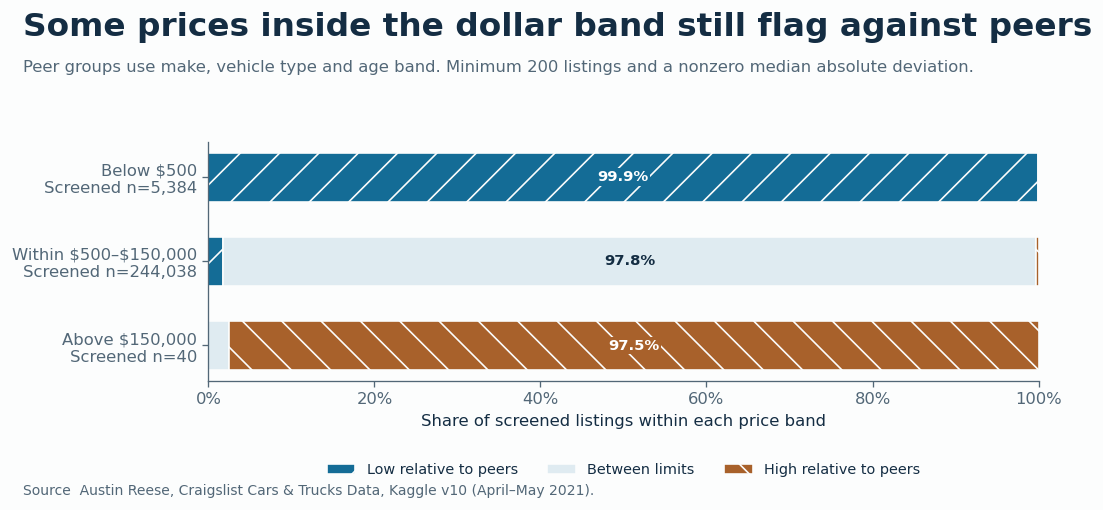

In [7]:
overlap, peer_sensitivity, peer_groups, complete_n = contextual_screening(positive)
screened_n = int(overlap["Peer screen n"].sum())
print(f"Complete make/type/age fields: {complete_n:,} of {len(prices):,} positive listings.")
print(f"Peer-screen coverage: {screened_n:,} listings across {peer_groups:,} groups.")
display(overlap.style.format({"Peer coverage %": "{:.2f}", **{k: "{:,.0f}" for k in overlap if k != "Peer coverage %"}}))
display(peer_sensitivity.style.format({"Screened n": "{:,.0f}", "Flagged n": "{:,.0f}", "Flagged %": "{:.2f}"}))
save_figure(peer_figure(overlap), OUTPUT, "05_peer_relative_screen")


Of the **244,038** eligible in-band listings, the peer method flags **4,427** as low relative to peers and **859** as high. The overall flag rate ranges from about **3.8% to 5.0%** across the stated cutoffs and group sizes. The above-band cohort has low peer coverage (**40 of 196 listings**), which limits what the overlap says about that tail.

## Takeaways

The median and middle spread give stable summaries across the two dollar cutoffs. Group selection can still change even when the center barely moves. Keep the positive-price sample for description and report both cohorts where later questions compare vehicle or state groups.

Zero prices, round numbers and extreme asks merit different checks. When a listing is unusual relative to its peers, the price could reflect features missing from the file. Use the flags to guide review and keep the cleaning rules visible in downstream results.


### Export aggregate evidence

The local figure directory contains PNG and PDF versions of the five plots and a JSON file of the aggregate inputs. The group tables include support and retain both price-screen denominators.


In [8]:
def records(table, index_name):
    named = table.rename_axis(index_name).reset_index()
    return json.loads(named.to_json(orient="records"))

summary = {
    "source": "Austin Reese, Craigslist Cars & Trucks Data, Kaggle v10",
    "source_rows": len(source_prices),
    "positive_rows": len(prices),
    "price_band_rows": len(band),
    "price_band_usd": [LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW],
    "audit": records(source_audit, "price_category"),
    "distribution_usd": records(distribution, "cohort"),
    "tail_probabilities": records(tails, "rule"),
    "above_band_share_of_arithmetic_price_sum": float(high_sum_share),
    "price_endings": records(endings, "ending"),
    "whole_dollar_rows": whole_n,
    "frequent_amounts": records(frequent.to_frame(), "asking_price_usd"),
    "vehicle_types": records(types.loc[types["Positive"].ge(1000), columns], "vehicle_type"),
    "states": records(states.loc[states["Positive"].ge(1000), columns], "state"),
    "manufacturers": records(makes.loc[makes["Positive"].ge(1000), columns], "manufacturer"),
    "peer_screen": records(overlap, "price_band"),
    "peer_sensitivity": json.loads(peer_sensitivity.to_json(orient="records")),
    "peer_complete_rows": complete_n,
    "peer_screened_rows": screened_n,
    "peer_group_count": peer_groups,
}
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved aggregate figures and summary to outputs/q1/.")


Saved aggregate figures and summary to outputs/q1/.
